<a href="https://colab.research.google.com/github/chimmy003/COU07506_WEEK2_240242496495/blob/main/COU07506_Week04_240242496495.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DIGIAL SIGNAL PROCESSING   WEEK4 LAB   
NAME: CHIMILO CHIMILO LABAN    
REG NO: 240242496495  
CLASS: BENG24COE   




Task 4.1 — A pole-zero plotting function
Objective: Create a Python function that plots the poles and zeros of a transfer function, displays its frequency response and checks stability.

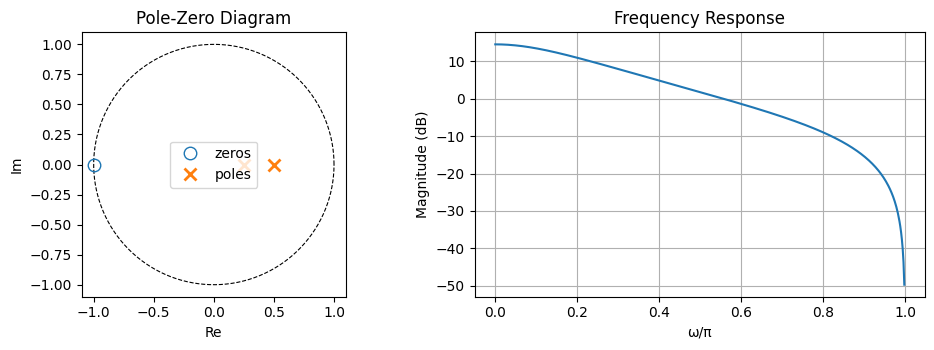

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    # Draw the unit circle
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)

    # Plot zeros and poles
    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="zeros")

    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p


b = [1, 1]
a = [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

# Pole-zero diagram
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-Zero Diagram")

# Frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Frequency Response")
ax2.set_xlabel("ω/π")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))



Task 4.2 — Inverse z-transform using residuez
Objective: Find the inverse z-transform using partial-fraction expansion, then compare the result with the output from signal.lfilter

In [3]:

# Find partial-fraction expansion
r, p, k = signal.residuez(
    [1],
    [1, -0.75, 0.125]
)

print("Residues:", r)
print("Poles:", p)
print("Direct polynomial part:", k)


Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct polynomial part: []


In [4]:

n = np.arange(10)

# Calculate impulse response using partial fractions
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

# Calculate impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(
    [1],
    [1, -0.75, 0.125],
    impulse
)

print("Using partial fractions:")
print(x_pf)

print("\nUsing lfilter:")
print(x_lf)

print("\nAre the results equal?")
print(np.allclose(x_pf, x_lf))


Using partial fractions:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Using lfilter:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Are the results equal?
True


In [5]:

r2, p2, k2 = signal.residuez(
    [1, 1],
    [1, -0.75, 0.125]
)

n = np.arange(10)

h = sum(ri * pi**n for ri, pi in zip(r2, p2)).real

print("Residues:", r2)
print("Poles:", p2)
print("Impulse response:", h)

# Verify using lfilter
impulse = np.zeros(10)
impulse[0] = 1

h_lfilter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Verification:", np.allclose(h, h_lfilter))


Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Impulse response: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Verification: True


TASK 4.3: Pole Position and Impulse Response
In this task, we investigate how changing the position of poles affects the impulse response and frequency response of a digital system.

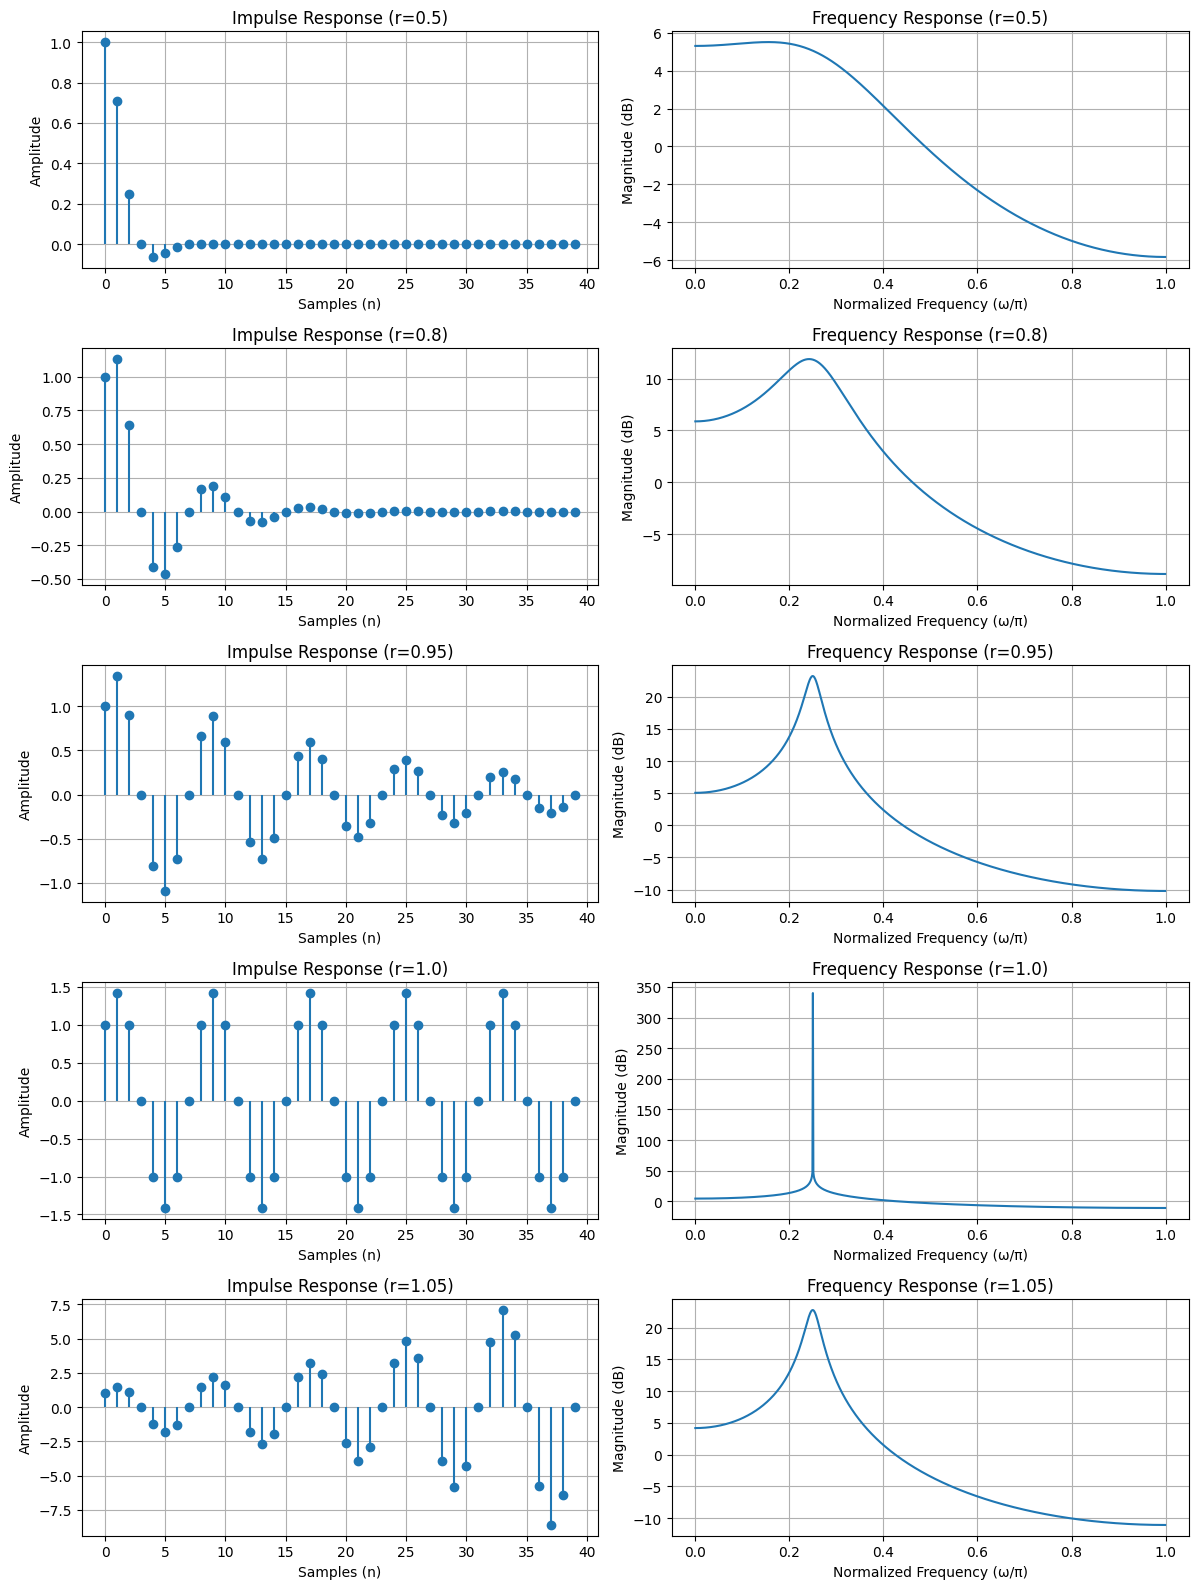

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole angle
theta = np.pi / 4

# Different pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Generate 40 samples
n = np.arange(40)

# Create an impulse signal
impulse = np.zeros(40)
impulse[0] = 1

# Create plots
fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for i, r in enumerate(r_values):

    # Denominator coefficients
    a = [1, -2*r*np.cos(theta), r**2]

    # Calculate impulse response
    h = signal.lfilter([1], a, impulse)

    # Calculate frequency response
    w, H = signal.freqz([1], a, worN=1024)

    # Plot impulse response
    axes[i, 0].stem(n, h, basefmt=" ")
    axes[i, 0].set_title(f"Impulse Response (r={r})")
    axes[i, 0].set_xlabel("Samples (n)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid()

    # Plot frequency response
    magnitude = 20 * np.log10(np.maximum(np.abs(H), 1e-12))

    axes[i, 1].plot(w/np.pi, magnitude)
    axes[i, 1].set_title(f"Frequency Response (r={r})")
    axes[i, 1].set_xlabel("Normalized Frequency (ω/π)")
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()


### Task 4.4 — Stability of given systems

We will now analyze the stability of the following systems:

* **(a)** $H_1(z) = \frac{1}{1 - 1.6z^{-1} + 0.89z^{-2}}$
* **(b)** $H_2(z) = \frac{1 + z^{-1}}{1 - 2.5z^{-1} + z^{-2}}$
* **(c)** $H_3(z) = \frac{1}{1 + 0.5z^{-1} - 0.5z^{-2}}$
* **(d)** $H_4(z) = 1 - z^{-4}$

System (a): Poles = [0.8+0.5j 0.8-0.5j], Stable according to poles: True, Final amplitude h[99] = -0.0037
System (b): Poles = [2.  0.5], Stable according to poles: False, Final amplitude h[99] = 1267650600228229401496703205376.0000
System (c): Poles = [-1.   0.5], Stable according to poles: False, Final amplitude h[99] = -0.6667
System (d): Poles = [], Stable according to poles: True, Final amplitude h[99] = 0.0000


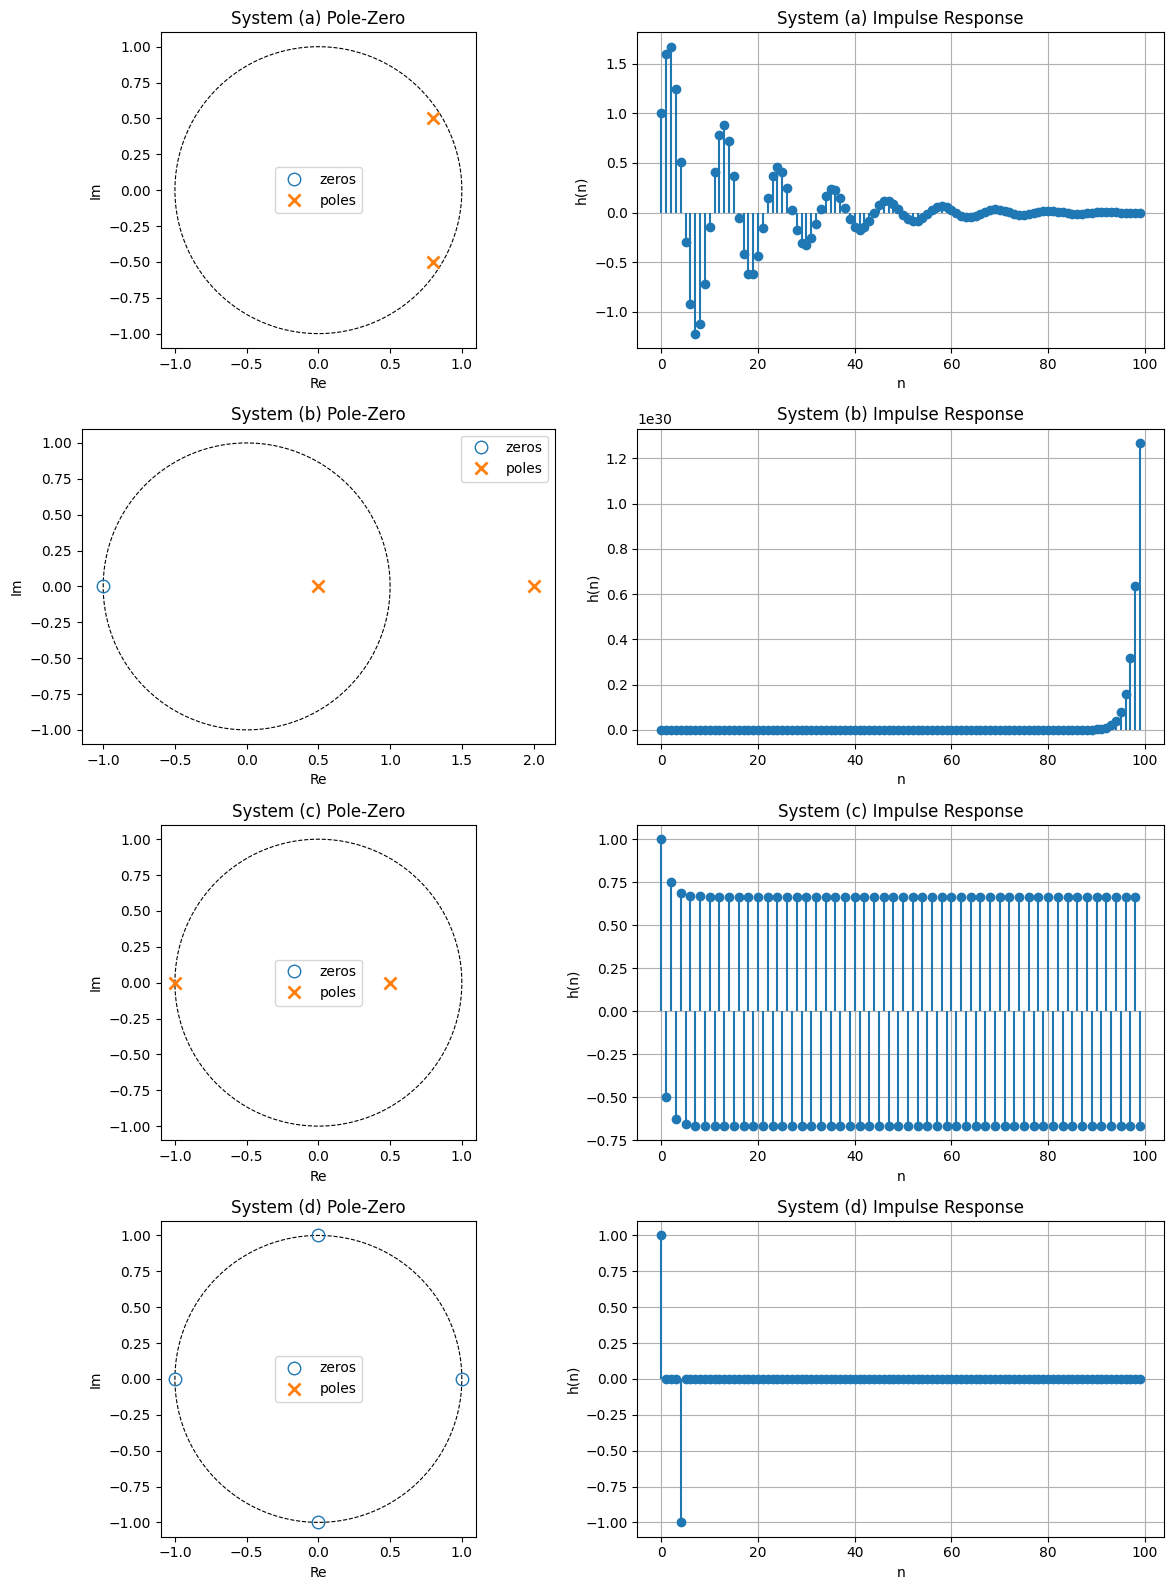

In [7]:
# Define numerator and denominator coefficients for each system
systems = {
    "a": ([1], [1, -1.6, 0.89]),
    "b": ([1, 1], [1, -2.5, 1]),
    "c": ([1], [1, 0.5, -0.5]),
    "d": ([1, 0, 0, 0, -1], [1])
}

# Create a plot layout for 4 systems
fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, (key, (b, a)) in enumerate(systems.items()):
    # Plot pole-zero diagram
    plt.sca(axes[i, 0])
    z, p = zplane(b, a, ax=axes[i, 0])
    axes[i, 0].set_title(f"System ({key}) Pole-Zero")

    # Compute impulse response for 100 samples to verify stability
    n_samples = 100
    impulse = np.zeros(n_samples)
    impulse[0] = 1.0
    h_n = signal.lfilter(b, a, impulse)

    # Plot impulse response
    axes[i, 1].stem(np.arange(n_samples), h_n, basefmt=" ")
    axes[i, 1].set_title(f"System ({key}) Impulse Response")
    axes[i, 1].set_xlabel("n")
    axes[i, 1].set_ylabel("h(n)")
    axes[i, 1].grid(True)

    # Check and print stability criteria
    stable_poles = np.all(np.abs(p) < 1)
    grows = np.abs(h_n[-1]) > np.abs(h_n[0]) if len(p) > 0 else False
    print(f"System ({key}): Poles = {p}, Stable according to poles: {stable_poles}, Final amplitude h[99] = {h_n[-1]:.4f}")

plt.tight_layout()
plt.show()

### Task 4.5 — Design a resonator

**Objective:** Design a second-order bandpass resonator with:
- Sampling frequency $f_s = 8\text{ kHz}$
- Peak frequency $f_0 = 1\text{ kHz}$
- Pole radius $r = 0.97$
- Zeros at $z = \pm 1$ to completely block DC ($0\text{ Hz}$) and $f_s/2$ ($4\text{ kHz}$).

/tmp/ipykernel_1610/588519794.py:34: RuntimeWarning: divide by zero encountered in log10
  ax2.plot(freqs_hz, 20 * np.log10(np.abs(H)))


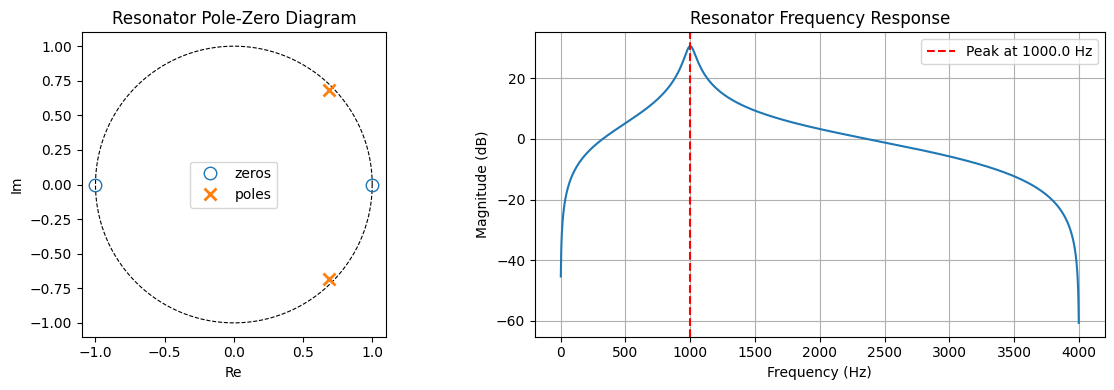

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio

# Design Parameters
fs = 8000.0  # Sampling rate in Hz
f0 = 1000.0  # Peak frequency in Hz
r = 0.97

# Calculate pole angle (theta)
theta = 2 * np.pi * f0 / fs

# Zeros at z = 1 and z = -1 -> (z - 1)(z + 1) = z^2 - 1
# In powers of z^-1: B(z) = 1 - z^-2
b_res = [1, 0, -1]

# Conjugate poles at r * e^(+/- j * theta)
# (z - r*e^(j*theta))(z - r*e^(-j*theta)) = z^2 - 2*r*cos(theta)*z + r^2
# In powers of z^-1: A(z) = 1 - 2*r*cos(theta)*z^-1 + r^2*z^-2
a_res = [1, -2 * r * np.cos(theta), r**2]

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Pole-Zero Diagram
z_res, p_res = zplane(b_res, a_res, ax1)
ax1.set_title("Resonator Pole-Zero Diagram")

# Frequency Response in Hz
w, H = signal.freqz(b_res, a_res, worN=2048)
freqs_hz = w * fs / (2 * np.pi)

ax2.plot(freqs_hz, 20 * np.log10(np.abs(H)))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.axvline(f0, color='r', linestyle='--', label=f'Peak at {f0} Hz')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Now we apply the designed resonator filter to 2 seconds of white noise, and listen to the bandpass filtered result.

In [9]:
# Generate 2 seconds of white noise
duration = 2.0
t = np.arange(int(fs * duration))
white_noise = np.random.normal(0, 1, len(t))

# Apply the resonator filter
y = signal.lfilter(b_res, a_res, white_noise)

# Normalize audio to prevent clipping
y = y / np.max(np.abs(y))

# Play the audio
Audio(y, rate=int(fs))

## AI Statement

ChatGPT was used to assist in understanding the laboratory tasks, writing Python code, and explaining the results. All work was reviewed and tested by the student.